# Uniaxial compression

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import xara
from xara.units import create_units

if "thesis" in plt.style.available:
    plt.style.use("thesis")

units = create_units(length="inch", force="kip")

## Common parameters

In [ ]:
Fy = 50*units.ksi
E  = 29000*units.ksi
nu = 0.3


ec0 = 0.003

alpha = 0

strain_history = np.linspace(0.0, 4 * ec0, 200)

Xo = 0.6*abs(Fy)*units.ksi


G = E/2./(1. +    nu)
K = E/3./(1. - 2.*nu)

## Loading test

`UniaxialTest` builds a unit cube with one `SSPbrick`. 
The bottom and two side coordinate planes prevent rigid motion; the other side faces are free. 
The top face moves uniformly in the axial direction. Displacement control follows the prescribed strain history, including post-peak softening. An optional `configure(model, material_tag, element_tag)` callback can set material stages before analysis.

In [3]:
from xara.examples.material import UniaxialTest

In [4]:
uniaxial_test = UniaxialTest(strain_history)

## Results


{'name': 1, 'type': 'NonlinearJ2', 'E': 29000, 'nu': 0.3, 'Fy': 50, 'Q': [10, 0], 'b': [800, 0], 'C': [0], 'gamma': [0], 'Hiso': 0, 'gtol': 1e-16, 'MaxIter': 15, 'density': 0}
{'name': 1, 'type': 'NonlinearJ2', 'E': 29000, 'nu': 0.3, 'Fy': 50, 'Q': [0, 0], 'b': [0, 0], 'C': [4350], 'gamma': [500], 'Hiso': 0, 'gtol': 1e-16, 'MaxIter': 15, 'density': 0}
{'name': 1, 'type': 'MisesBoundingSurface', 'E': 29000, 'nu': 0.3, 'R': 48.9898, 'r': 40.8248, 'Hy': 0, 'h': 14500, 'm': 1, 'H0': 0, 'memory': 0, 'gtol': 1e-10, 'MaxIter': 50, 'density': 0}


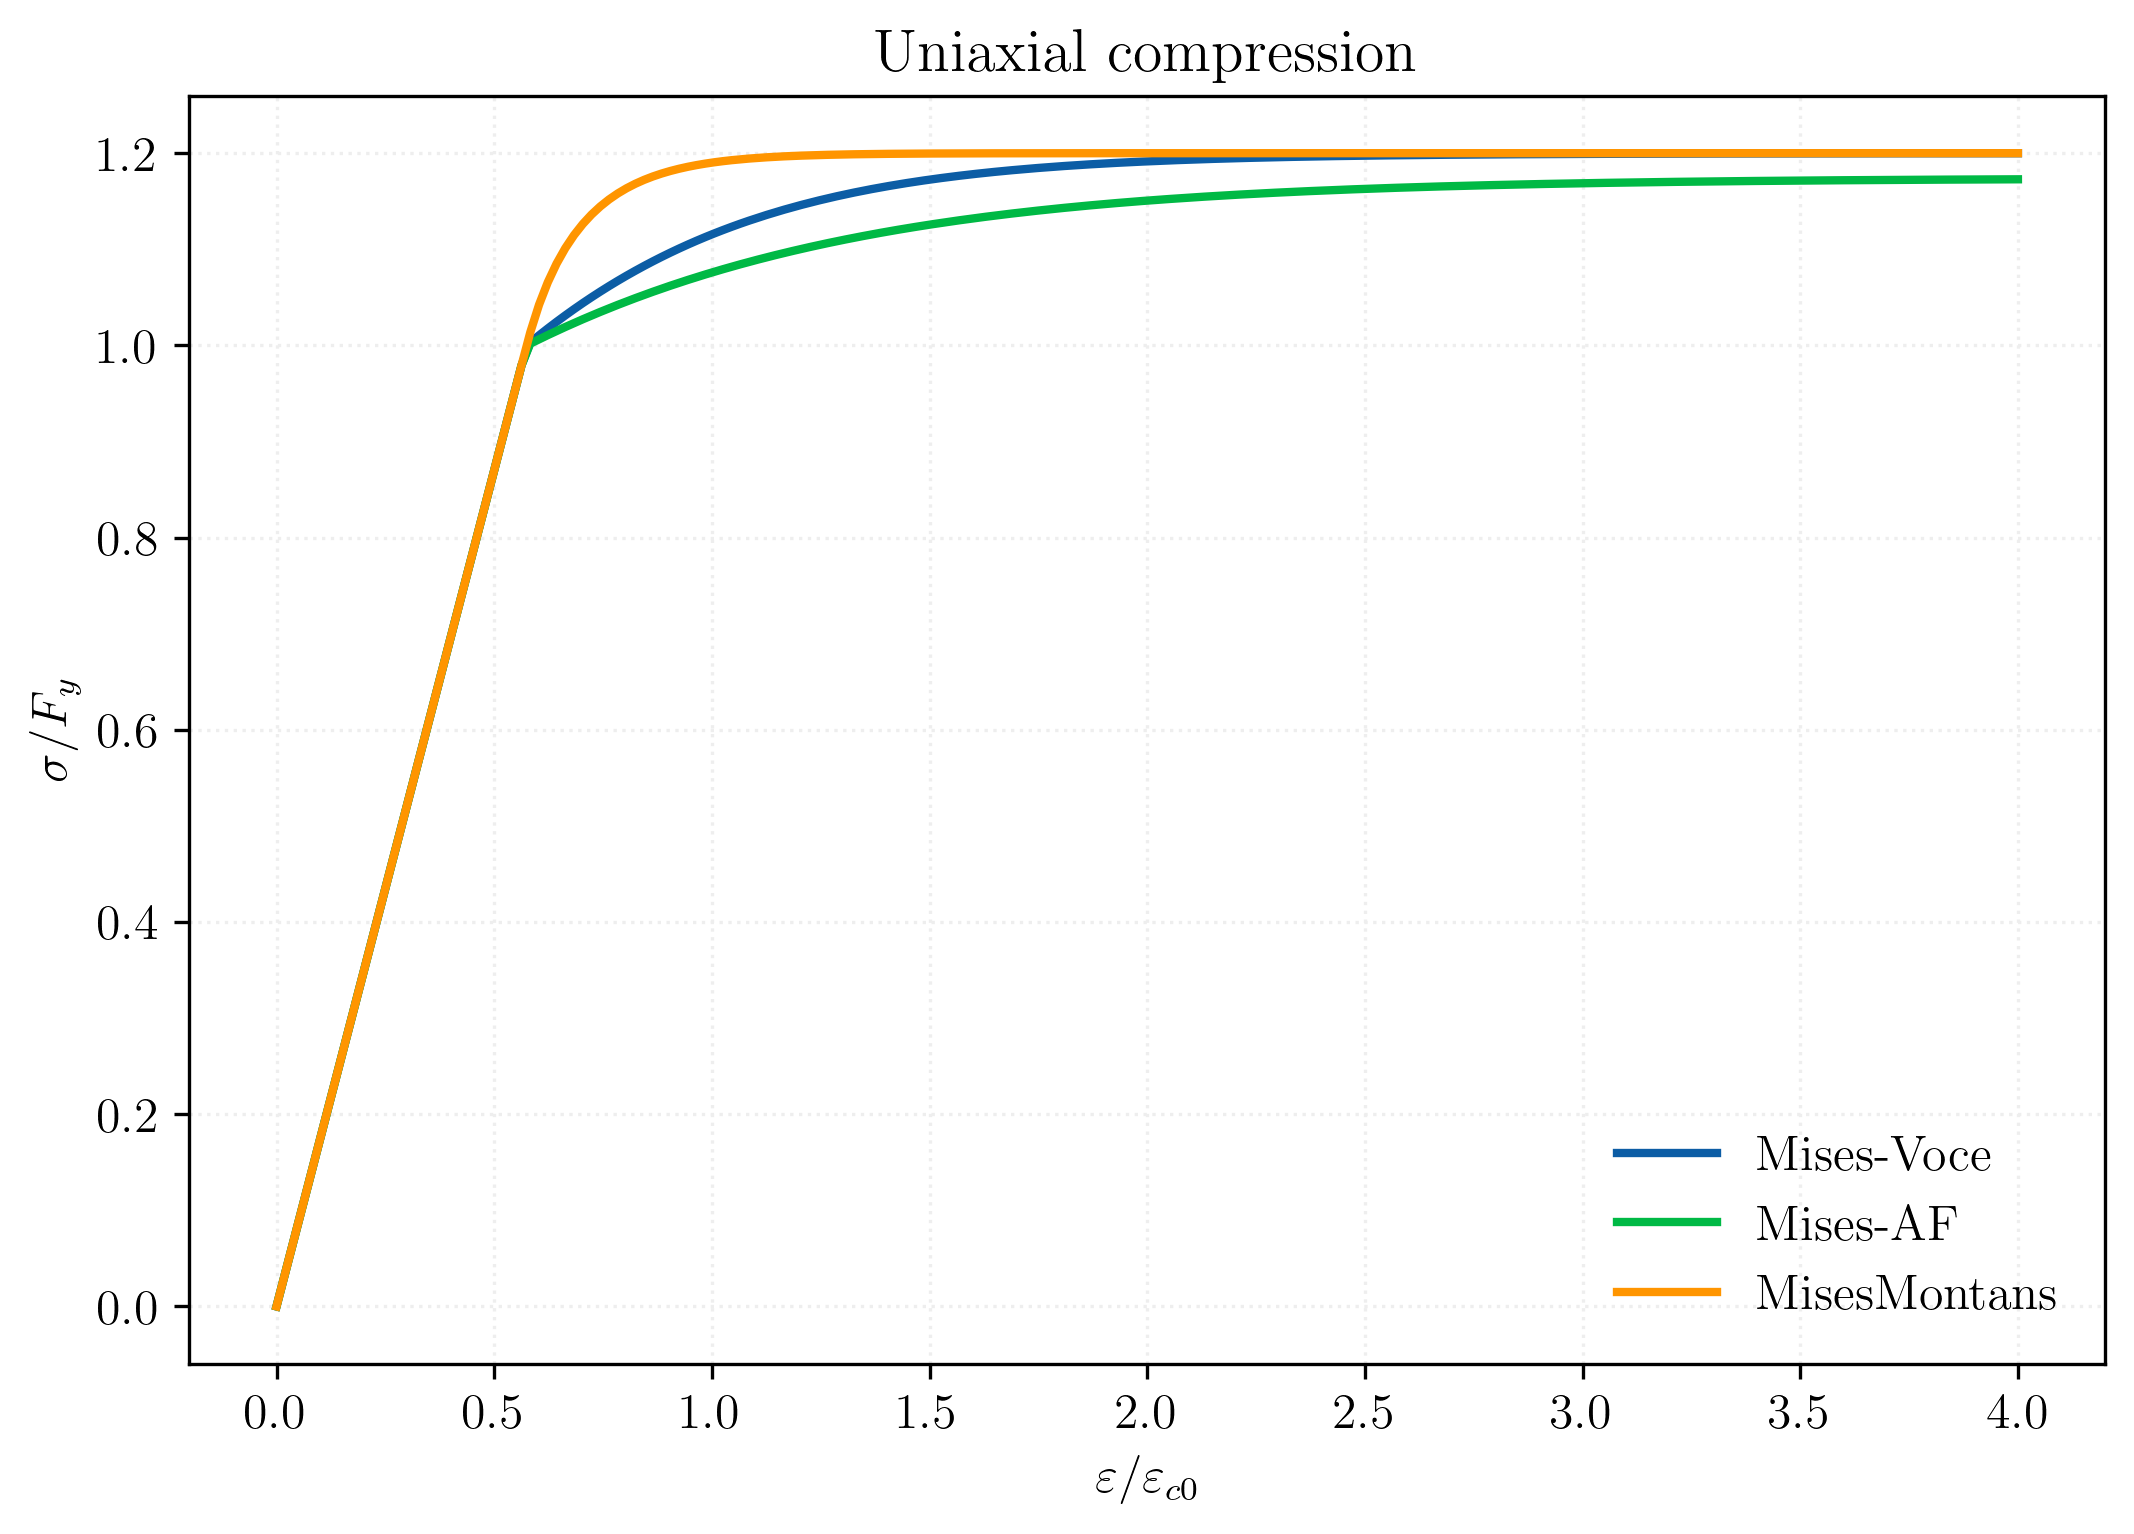

In [ ]:
c = 1
materials = {
    "Mises-Voce": xara.MultiaxialMaterial(
        "PlasticJ2", E=E, nu=nu,
        Fy=abs(Fy),
        Fs=1.2*abs(Fy),
        delta=800,
        Hiso=0.0*E,
        Hkin=0.0,
    ),
    "Mises-AF": xara.MultiaxialMaterial(
        "PlasticJ2", E=E, nu=nu,
        Fy=abs(Fy),
        Hiso=0.0*E,
        Hkin=0.15*E,
        gamma=500
    ),

    "Mises-Montans": xara.MultiaxialMaterial(
        "MisesBoundingSurface", E=E, nu=nu, 
        Fy=1.0*c*Fy,
        Fs=1.2*c*Fy,
        Hy=0, #0.1*Ec,
        m=1,
        h=0.5*E, #0.1*G,
        H0=0
    ),

    # "Drucker02": xara.MultiaxialMaterial(
    #     "DruckerPlasticity02", E=Ec, nu=nu,
    #     alpha=abs(Fy)*(np.sqrt(2/3) - alpha),
    #     gamma=0,
    #     beta=0.0,
    #     theta=alpha,
    #     Xo=Xo,
    #     D=1/Xo,
    #     T=Fy,
    #     W=0.08,
    #     R=1,
    # ),
}

fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
for label, material in materials.items():
    print(material.asdict())
    result = uniaxial_test.run(material, label)
    ax.plot(result.axial_strain/ec0,  result.axial_stress / Fy,
            lw=2, label=label)

ax.set_xlabel(r"$\varepsilon/\varepsilon_{c0}$")
ax.set_ylabel(r"$\sigma/F_y$")
ax.set_title("Uniaxial compression")
ax.legend();